# I. Identificación del proyecto

| Campo | Detalle |
|---|---|
| **Curso** | Exploración Inteligente de Datos (MCDI503) · Magíster en Ciencia de Datos e IA · Universidad Andrés Bello |
| **Avance** | Fase 1 · EDA mínimo viable reproducible |
| **Proyecto** | Factores asociados a la supervivencia de los pasajeros del Titanic: un primer EDA reproducible |
| **Integrantes** | Hernán Saavedra · Lenin Morales · Rodrigo Gómez · Grupo 1 |
| **Docente** | ✍️ COMPLETAR |
| **Dataset** | `titanic`, distribuido por seaborn (`sns.load_dataset("titanic")`; Waskom, s. f.) |
| **Fecha** | ✍️ COMPLETAR |

**Propósito general del análisis.** Caracterizar la estructura y calidad del dataset `titanic` y describir cómo se distribuyen sus variables principales y cómo se relacionan con la supervivencia, como base documentada para las fases posteriores del proyecto.

> **Cómo leer este notebook.** Cada bloque sigue la secuencia *pregunta → acción → resultado → decisión*.
> Las preguntas exploratorias se numeran **P1–P4** (sección II) y las decisiones **D1–D6** (sección V); ambas se citan en el informe PDF.
> Para reproducir el análisis desde cero: *Kernel → Restart & Run All*.

# II. Contexto y objetivo exploratorio

## II.1 Contexto del problema
El hundimiento del RMS Titanic (15 de abril de 1912) es uno de los casos más estudiados en análisis de datos. El dataset reúne información sociodemográfica y de viaje de 891 pasajeros —clase del boleto, sexo, edad, tarifa, puerto de embarque y acompañantes— junto con su desenlace (sobrevivió / no sobrevivió). **Cada fila representa a un pasajero.**
Antes de cualquier inferencia o modelamiento, es necesario conocer la estructura del dataset, la calidad de sus registros y los patrones iniciales que muestra, porque de ello dependen las decisiones de las fases siguientes.

## II.2 Objetivo exploratorio
Describir la estructura, la calidad y el comportamiento de las variables del dataset `titanic`, e identificar de forma preliminar qué características de los pasajeros se asocian a diferencias en la supervivencia, documentando cada decisión exploratoria de manera reproducible.

## II.3 Preguntas exploratorias iniciales

| ID | Pregunta exploratoria | Se responde en |
|---|---|---|
| **P1** | ¿Qué variables presentan valores faltantes, duplicados o redundancias, y cómo condicionan el análisis? | §III.3, §IV.1, §V |
| **P2** | ¿Cómo se distribuyen la edad, la tarifa y el tamaño del grupo familiar (asimetrías, valores extremos)? | §IV.2, §V-D6 |
| **P3** | ¿La tasa de supervivencia difiere según el sexo y la clase del boleto? | §VI.1 |
| **P4** | ¿Cómo varía la tarifa entre clases y la supervivencia según el tamaño del grupo familiar? | §VI.2, §VI.3 |

# III. Carga y revisión inicial de datos

## III.1 Librerías y registro del entorno
Trabajaremos con `pandas` (manipulación de datos), `numpy` (apoyo numérico) y `seaborn`/`matplotlib` (visualización).
Se registran las versiones para que otra persona pueda reproducir el mismo entorno.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

print(f"Python     : {sys.version.split()[0]}")
print(f"pandas     : {pd.__version__}")
print(f"numpy      : {np.__version__}")
print(f"seaborn    : {sns.__version__}")
print(f"matplotlib : {matplotlib.__version__}")

Python     : 3.13.18
pandas     : 3.0.5
numpy      : 2.5.3
seaborn    : 0.13.2
matplotlib : 3.11.2


## III.2 Carga del dataset con copia local
`sns.load_dataset()` descarga el CSV desde el repositorio `mwaskom/seaborn-data` (GitHub) en cada ejecución. Para que todo el equipo trabaje sobre **el mismo archivo**, el repositorio incluye una copia versionada en `datos/titanic.csv` (generada con `scripts/descargar_datos.py`) y el análisis se ejecuta siempre sobre ella.
El DataFrame original (`titanic_raw`) **no se modifica**; las transformaciones se hacen sobre una copia en la sección V.

In [2]:
# Se ubica la raíz del proyecto (carpeta que contiene datos/titanic.csv),
# para que el notebook funcione tanto desde la raíz del repo como desde notebooks/
directorio_actual = Path.cwd().resolve()
raiz_proyecto = next(p for p in [directorio_actual, *directorio_actual.parents]
                     if (p / "datos" / "titanic.csv").exists())

RUTA_DATOS = raiz_proyecto / "datos" / "titanic.csv"
print("Dataset local:", RUTA_DATOS.relative_to(raiz_proyecto))

titanic_raw = pd.read_csv(RUTA_DATOS)
titanic_raw.head()

Dataset local: datos/titanic.csv


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## III.3 Inspección inicial del dataset
Un EDA mínimo viable no empieza haciendo gráficos sin contexto. Antes conviene responder preguntas básicas:

- ¿Cuántas filas y columnas tiene el dataset?
- ¿Qué tipo de variables contiene?
- ¿Hay valores nulos, duplicados o columnas redundantes?
- ¿Qué representa cada columna?

Esta inspección permite detectar faltantes (como en `age` o `deck`) o duplicidad conceptual (por ejemplo, `survived` vs `alive`, o `pclass` vs `class`) antes de profundizar.

In [3]:
print("Dimensiones del dataset:", titanic_raw.shape)
titanic_raw.info()

print("\nValores nulos por columna:")
print(titanic_raw.isnull().sum().sort_values(ascending=False))

print("\nFilas duplicadas exactas:", titanic_raw.duplicated().sum())

Dimensiones del dataset: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB

Valores nulos por columna:
deck           688
age            177
embarked         2
emba

In [4]:
titanic_raw.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True
7,0,3,male,2.0,3,1,21.0750,S,Third,child,False,NaN,Southampton,no,False
8,1,3,female,27.0,0,2,11.1333,S,Third,woman,False,NaN,Southampton,yes,False
9,1,2,female,14.0,1,0,30.0708,C,Second,child,False,NaN,Cherbourg,yes,False


### Diccionario de variables
Tipo **técnico** (cómo lo guarda pandas) frente a tipo **estadístico** (cómo debe analizarse). Esta distinción determina el resumen y el gráfico adecuados.

In [5]:
tipo_estadistico = {
    "survived": "binaria (variable de interés)", "pclass": "categórica ordinal (1 > 2 > 3)",
    "sex": "categórica nominal", "age": "numérica continua", "sibsp": "numérica discreta",
    "parch": "numérica discreta", "fare": "numérica continua", "embarked": "categórica nominal",
    "class": "categórica ordinal", "who": "categórica nominal", "adult_male": "binaria",
    "deck": "categórica nominal", "embark_town": "categórica nominal", "alive": "binaria",
    "alone": "binaria",
}
diccionario = pd.DataFrame({
    "tipo_pandas": titanic_raw.dtypes.astype(str),
    "tipo_estadistico": pd.Series(tipo_estadistico),
    "n_unicos": titanic_raw.nunique(),
    "n_nulos": titanic_raw.isna().sum(),
    "pct_nulos": (titanic_raw.isna().mean() * 100).round(1),
})
diccionario

,tipo_pandas,tipo_estadistico,n_unicos,n_nulos,pct_nulos
survived,int64,binaria (variable de interés),2,0,0.0
pclass,int64,categórica ordinal (1 > 2 > 3),3,0,0.0
sex,str,categórica nominal,2,0,0.0
age,float64,numérica continua,88,177,19.9
sibsp,int64,numérica discreta,7,0,0.0
parch,int64,numérica discreta,7,0,0.0
fare,float64,numérica continua,248,0,0.0
embarked,str,categórica nominal,3,2,0.2
class,str,categórica ordinal,3,0,0.0
who,str,categórica nominal,3,0,0.0


**Primeras observaciones (responde parcialmente P1):** ✍️ COMPLETAR (2-4 viñetas). Pistas: tamaño del dataset; `pclass` es número pero se comporta como orden; qué columnas tienen nulos y en qué magnitud; existencia de duplicados.

# IV. Exploración preliminar

## IV.1 Estadísticas descriptivas iniciales
Para las variables numéricas observamos media, mediana, dispersión, cuartiles, mínimos y máximos. Para las categóricas, frecuencias absolutas y relativas y el equilibrio entre categorías.
Estas salidas no sustituyen a las visualizaciones, pero ayudan a detectar rápidamente asimetrías, tarifas extremas (`fare`) o desequilibrios de clase y supervivencia.

In [6]:
num_cols = ["survived", "pclass", "age", "sibsp", "parch", "fare"]
resumen_num = titanic_raw[num_cols].describe().T
resumen_num["mediana"] = titanic_raw[num_cols].median()
resumen_num["IQR"] = resumen_num["75%"] - resumen_num["25%"]
resumen_num.round(2)

,count,mean,std,min,25%,50%,75%,max,mediana,IQR
survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00,0.00,1.00
pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00,3.00,1.00
age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00,28.00,17.88
sibsp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00,0.00,1.00
parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00,0.00,0.00
fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33,14.45,23.09


In [7]:
cat_cols = ["sex", "class", "embark_town", "who", "alone", "alive", "deck"]
for col in cat_cols:
    tabla = pd.DataFrame({
        "n": titanic_raw[col].value_counts(dropna=False),
        "%": (titanic_raw[col].value_counts(dropna=False, normalize=True) * 100).round(1),
    })
    print(f"\nFrecuencias de {col}:")
    print(tabla)


Frecuencias de sex:
          n     %
sex              
male    577  64.8
female  314  35.2

Frecuencias de class:
          n     %
class            
Third   491  55.1
First   216  24.2
Second  184  20.7

Frecuencias de embark_town:
               n     %
embark_town           
Southampton  644  72.3
Cherbourg    168  18.9
Queenstown    77   8.6
NaN            2   0.2

Frecuencias de who:
         n     %
who             
man    537  60.3
woman  271  30.4
child   83   9.3

Frecuencias de alone:
         n     %
alone           
True   537  60.3
False  354  39.7

Frecuencias de alive:
         n     %
alive           
no     549  61.6
yes    342  38.4

Frecuencias de deck:
        n     %
deck           
NaN   688  77.2
C      59   6.6
B      47   5.3
D      33   3.7
E      32   3.6
A      15   1.7
F      13   1.5
G       4   0.4


## IV.2 Distribuciones univariantes  ·  *(P2)*
El objetivo no es "hacer gráficos", sino responder: ¿la distribución es simétrica o asimétrica?, ¿hay colas largas?, ¿hay valores extremos?, ¿dónde se concentran las observaciones?

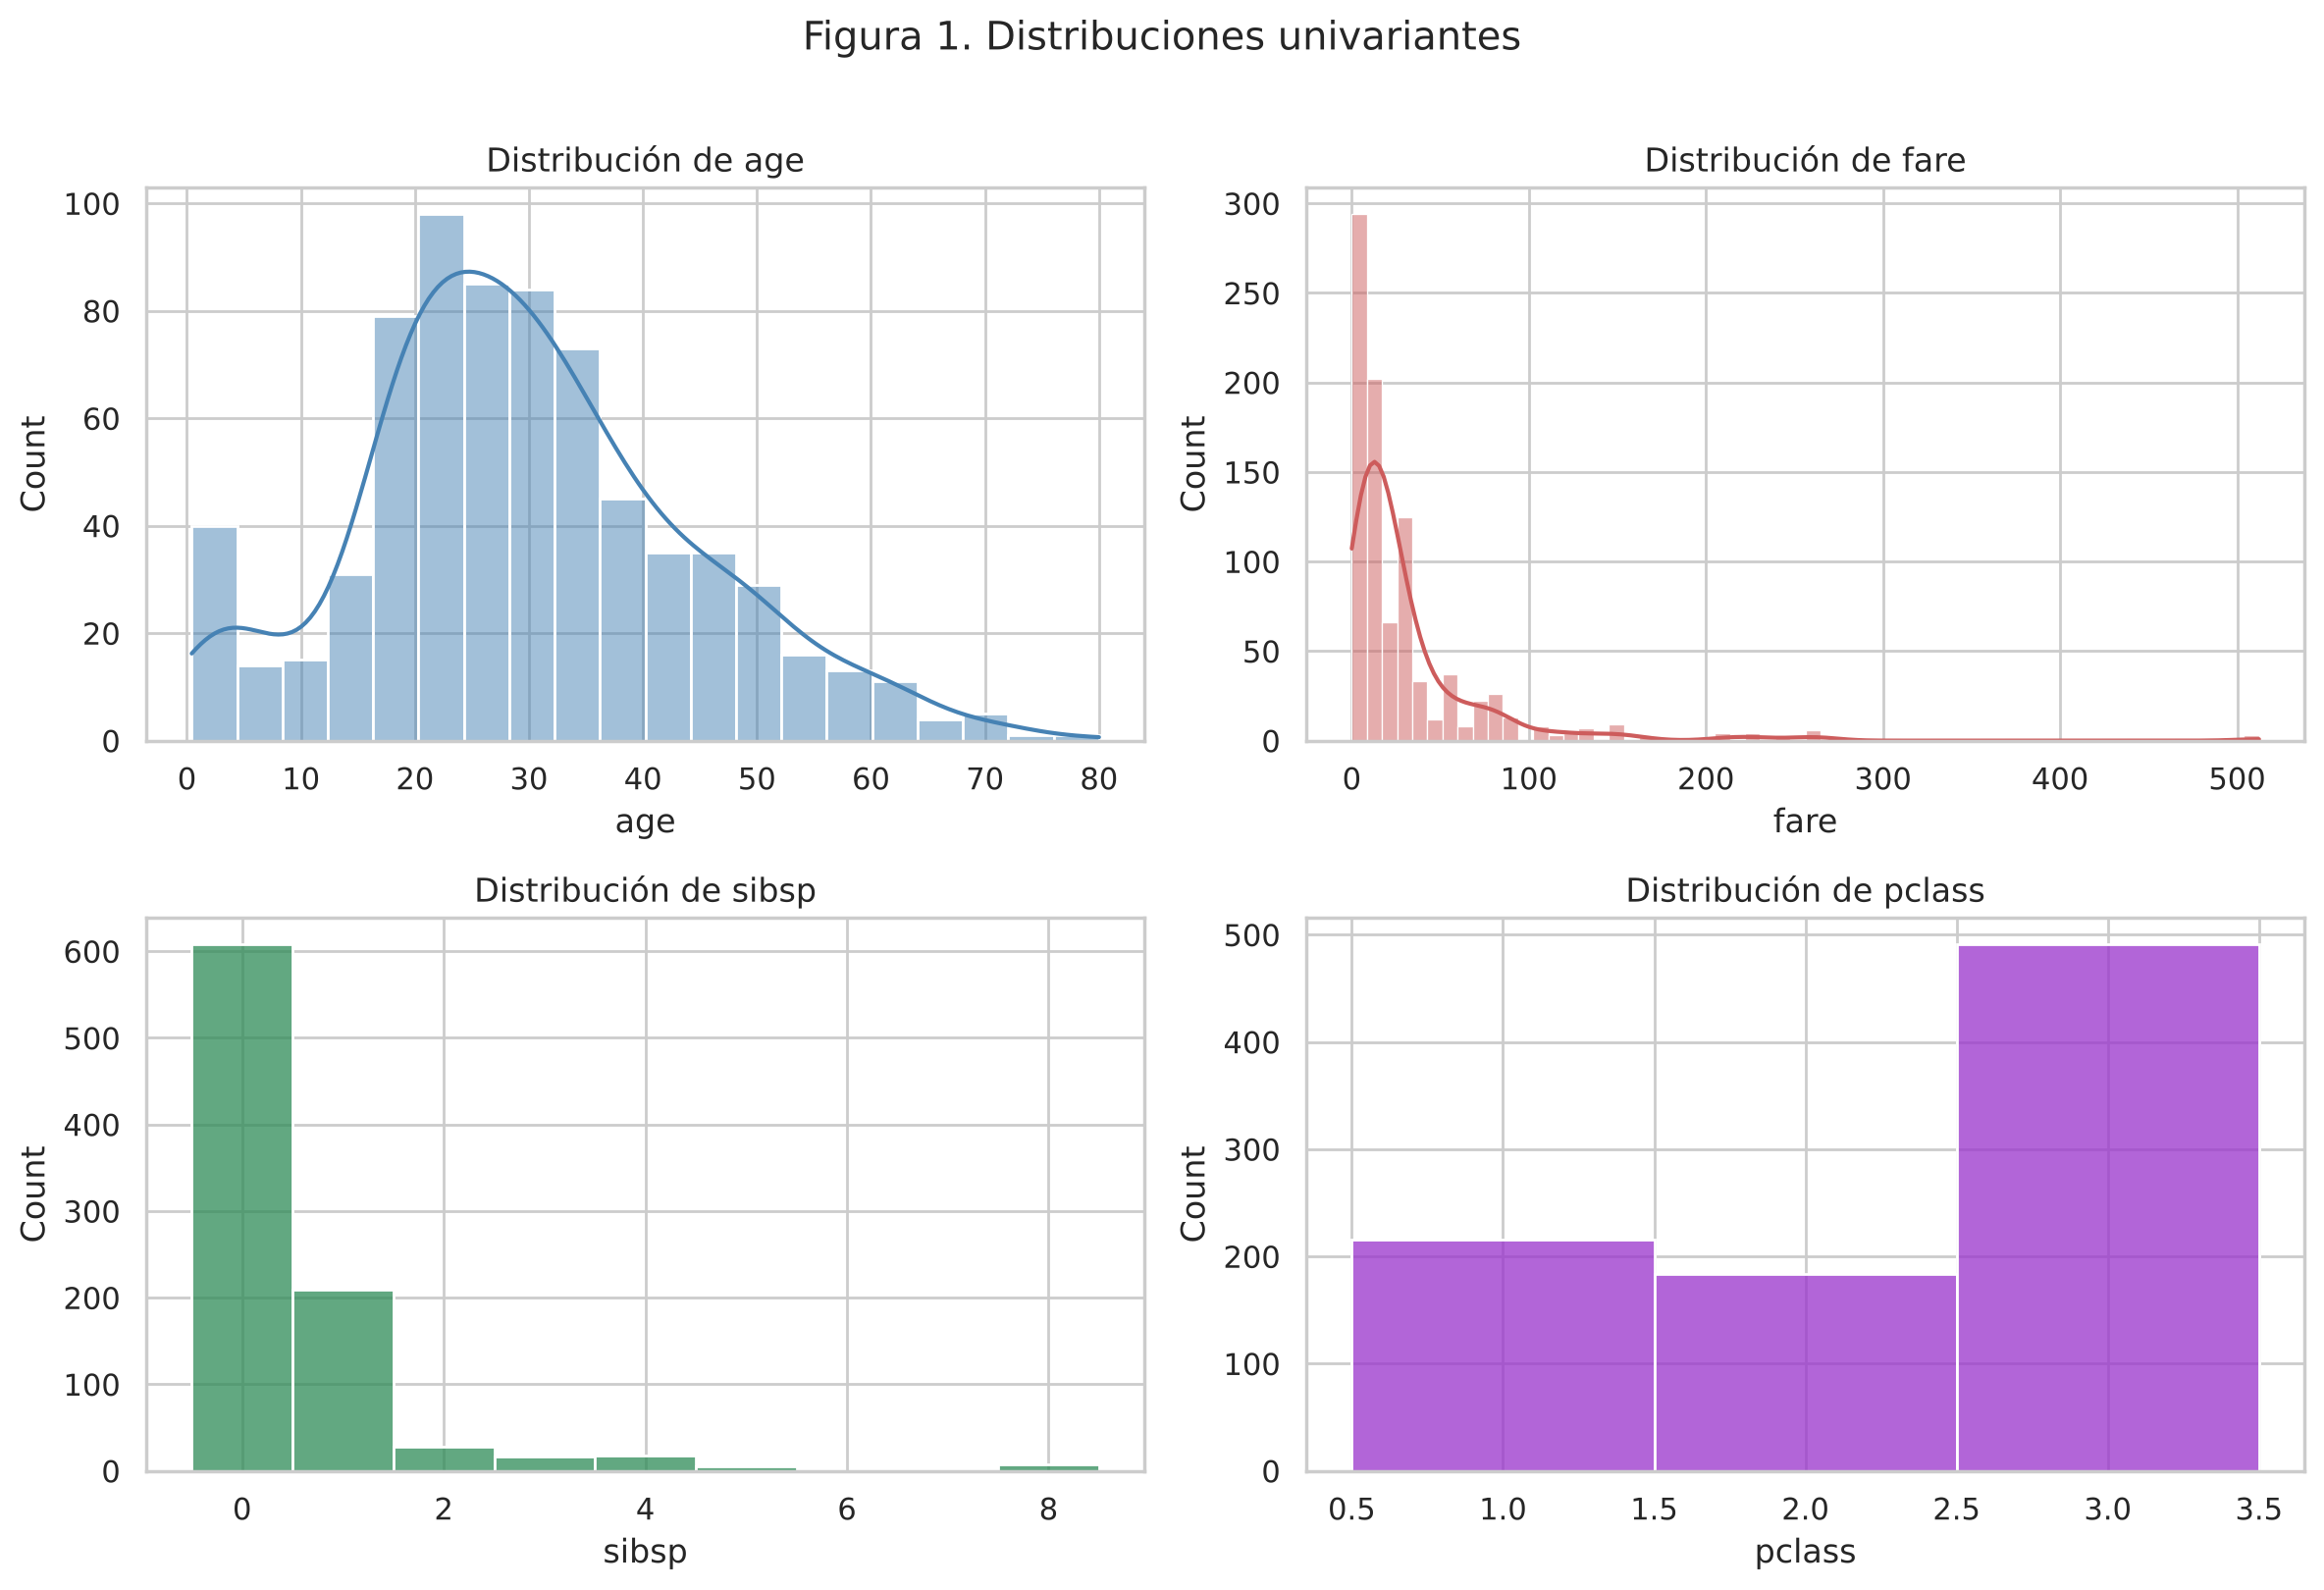

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(titanic_raw["age"].dropna(), kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Distribución de age")

sns.histplot(titanic_raw["fare"], kde=True, ax=axes[0, 1], color="indianred")
axes[0, 1].set_title("Distribución de fare")

sns.histplot(titanic_raw["sibsp"], discrete=True, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Distribución de sibsp")

sns.histplot(titanic_raw["pclass"], discrete=True, ax=axes[1, 1], color="darkorchid")
axes[1, 1].set_title("Distribución de pclass")

fig.suptitle("Figura 1. Distribuciones univariantes", y=1.01)
plt.tight_layout()
plt.show()

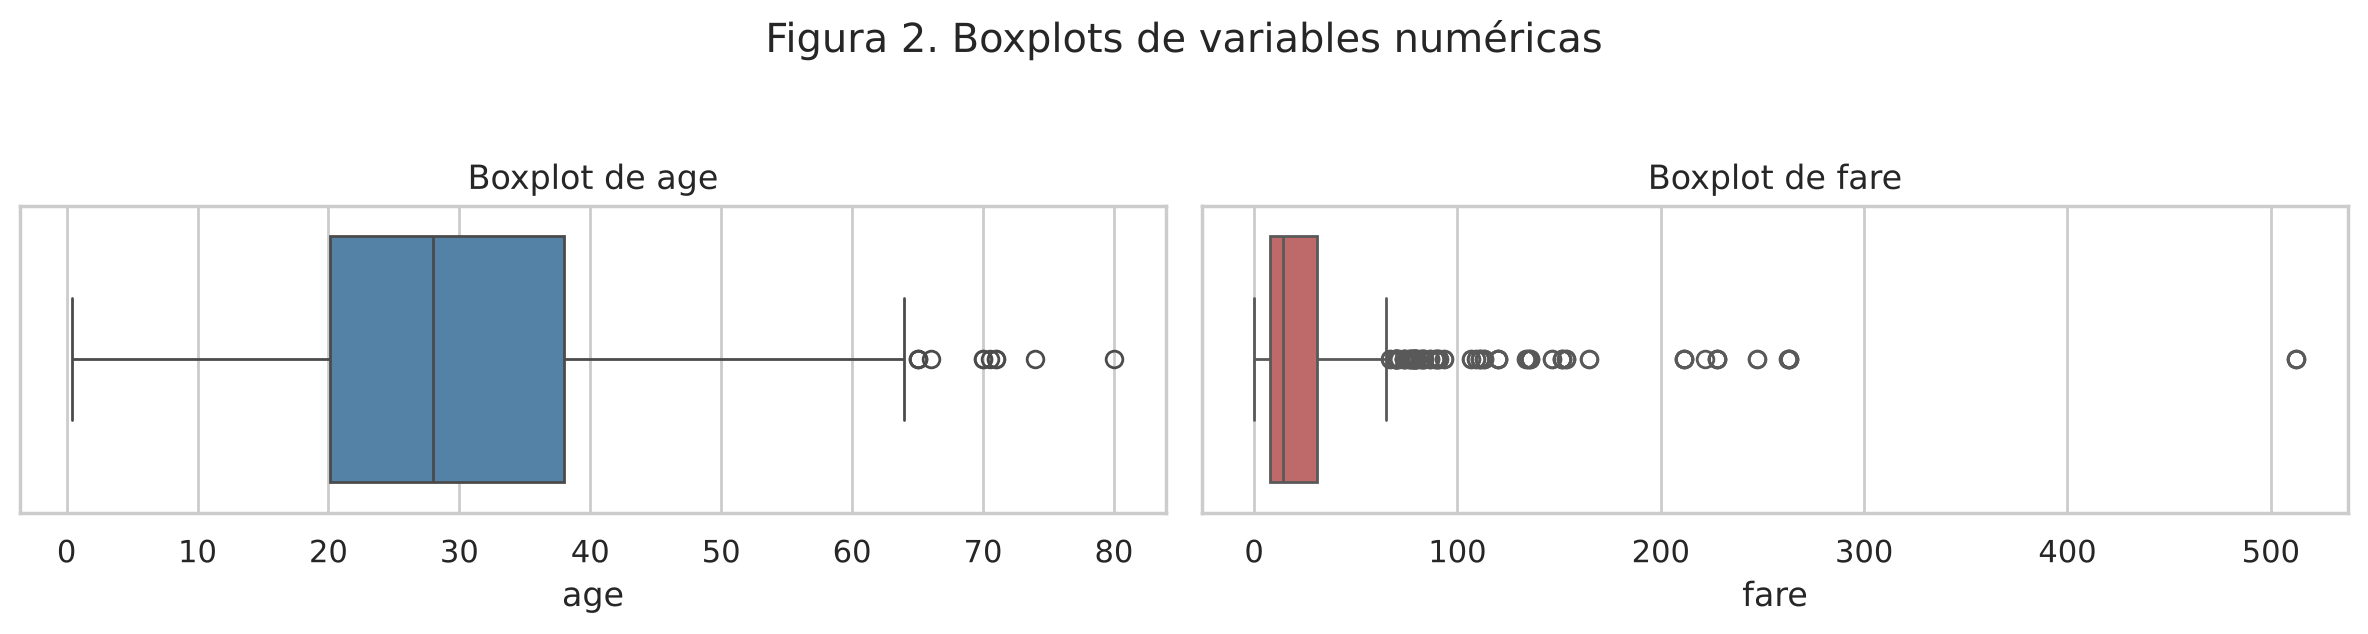

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))

sns.boxplot(x=titanic_raw["age"].dropna(), ax=axes[0], color="steelblue")
axes[0].set_title("Boxplot de age")

sns.boxplot(x=titanic_raw["fare"], ax=axes[1], color="indianred")
axes[1].set_title("Boxplot de fare")

fig.suptitle("Figura 2. Boxplots de variables numéricas", y=1.05)
plt.tight_layout()
plt.show()

In [10]:
# Outliers según regla del IQR (1,5 × IQR): pistas a revisar, no errores a borrar
def contar_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())

pd.Series({c: contar_outliers_iqr(titanic_raw[c].dropna()) for c in ["age", "fare"]},
          name="n_outliers_IQR")

age      11
fare    116
Name: n_outliers_IQR, dtype: int64

### Lectura de las distribuciones
- `age` muestra concentración en adultos jóvenes, con presencia infantil en la cola inferior y adultos mayores hacia la superior (con 177 nulos a considerar).
- `fare` presenta una fuerte asimetría positiva (cola larga a la derecha): la mayoría pagó tarifas bajas o moderadas y unos pocos registran montos muy elevados.
- `pclass` muestra que la tercera clase concentra a más de la mitad de los pasajeros.

✍️ COMPLETAR: comparar media y mediana de `fare` (Tabla IV.1) y comentar si los outliers parecen errores o casos reales.

## IV.3 Variables categóricas
Permite detectar categorías dominantes, desequilibrios y el contexto general del dataset.

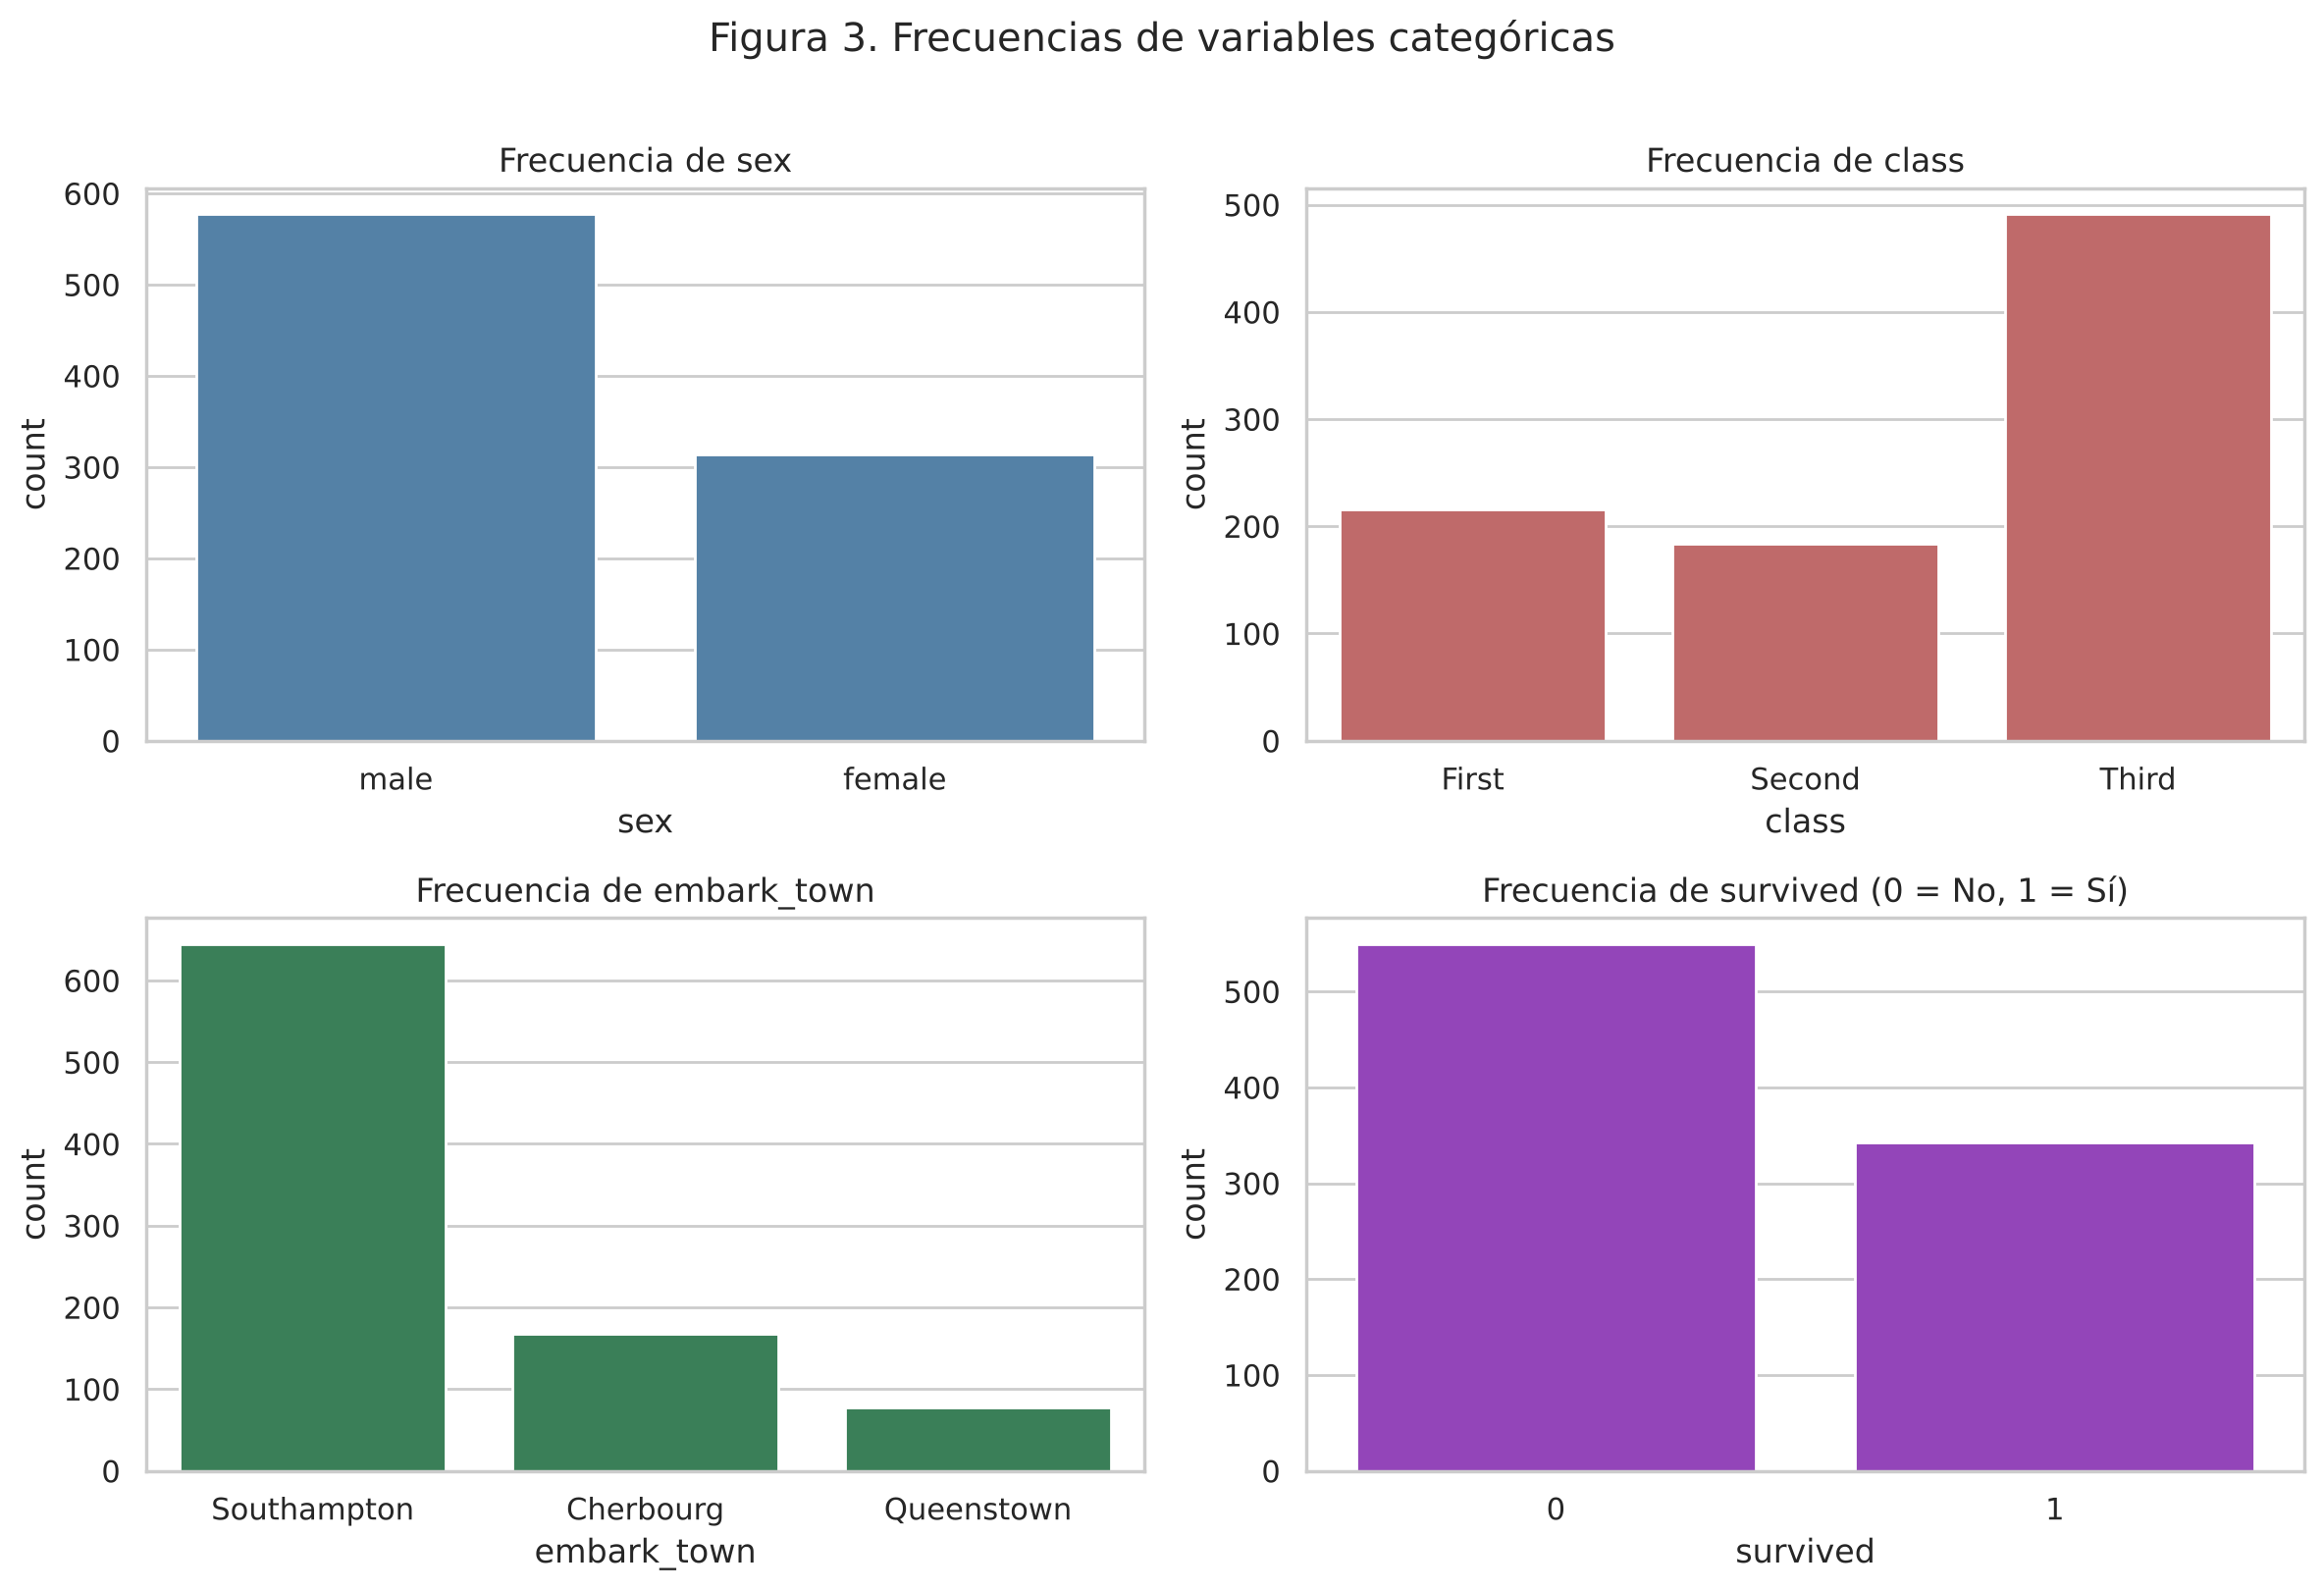

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(data=titanic_raw, x="sex", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Frecuencia de sex")

sns.countplot(data=titanic_raw, x="class", ax=axes[0, 1], color="indianred",
              order=["First", "Second", "Third"])
axes[0, 1].set_title("Frecuencia de class")

sns.countplot(data=titanic_raw, x="embark_town", ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Frecuencia de embark_town")

sns.countplot(data=titanic_raw, x="survived", ax=axes[1, 1], color="darkorchid")
axes[1, 1].set_title("Frecuencia de survived (0 = No, 1 = Sí)")

fig.suptitle("Figura 3. Frecuencias de variables categóricas", y=1.01)
plt.tight_layout()
plt.show()

✍️ COMPLETAR: ¿hay desbalances relevantes (p. ej., en `sex` o `survived`)? ¿Qué implican para comparar grupos?

# V. Decisiones y transformaciones iniciales  ·  *(P1)*

Cada decisión sigue el formato **evidencia → opciones → decisión → justificación → resultado intermedio**.
Se trabaja sobre una copia (`titanic_eda`) para conservar `titanic_raw` y comparar antes/después.

In [12]:
titanic_eda = titanic_raw.copy()
registro_decisiones = []

def registrar(id_dec, tema, decision, justificacion, efecto):
    registro_decisiones.append({"ID": id_dec, "Tema": tema, "Decisión": decision,
                                "Justificación": justificacion, "Resultado intermedio": efecto})

## D1. Filas duplicadas
**Evidencia:**

In [13]:
dup_mask = titanic_raw.duplicated(keep=False)
print("Filas duplicadas exactas:", titanic_raw.duplicated().sum())
print("Filas involucradas en duplicados:", dup_mask.sum())
print("¿Existe columna identificadora (passengerid, name, ticket)?",
      any(c in titanic_raw.columns for c in ["passengerid", "name", "ticket"]))
titanic_raw[dup_mask].sort_values(list(titanic_raw.columns)).head(6)

Filas duplicadas exactas: 107
Filas involucradas en duplicados: 160
¿Existe columna identificadora (passengerid, name, ticket)? False


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
144,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
757,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
658,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
733,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True


✍️ **COMPLETAR D1.** Sin identificador de pasajero, ¿dos filas idénticas son necesariamente la misma persona? Opciones: (a) eliminar · (b) conservar y documentar como limitación.

In [14]:
ELIMINAR_DUPLICADOS = False   # ✍️ ajustar según la decisión del equipo
if ELIMINAR_DUPLICADOS:
    titanic_eda = titanic_eda.drop_duplicates()

registrar("D1", "Duplicados", "✍️ COMPLETAR", "✍️ COMPLETAR", f"Filas tras D1: {len(titanic_eda)}")
print("Filas tras D1:", len(titanic_eda))

Filas tras D1: 891


## D2. Columnas redundantes
**Evidencia:** se verifica si algunas columnas son recodificaciones exactas de otras.

In [15]:
for a, b in [("survived", "alive"), ("pclass", "class"), ("embarked", "embark_town")]:
    print(f"\n{a} vs {b}")
    print(pd.crosstab(titanic_raw[a], titanic_raw[b]))

print("\n'alone' coincide con (sibsp + parch == 0):",
      (titanic_raw["alone"] == ((titanic_raw["sibsp"] + titanic_raw["parch"]) == 0)).all())


survived vs alive
alive      no  yes
survived          
0         549    0
1           0  342

pclass vs class
class   First  Second  Third
pclass                      
1         216       0      0
2           0     184      0
3           0       0    491

embarked vs embark_town
embark_town  Cherbourg  Queenstown  Southampton
embarked                                       
C                  168           0            0
Q                    0          77            0
S                    0           0          644

'alone' coincide con (sibsp + parch == 0): True


✍️ **COMPLETAR D2.** Si dos columnas dicen lo mismo, ¿cuál conservar y por qué? Considere también `who` y `adult_male` frente a `sex`.

In [16]:
COLUMNAS_REDUNDANTES = []   # ✍️ ej.: ["alive", ...]
titanic_eda = titanic_eda.drop(columns=COLUMNAS_REDUNDANTES)
registrar("D2", "Columnas redundantes", f"Se descartan: {COLUMNAS_REDUNDANTES}", "✍️ COMPLETAR",
          f"Columnas tras D2: {titanic_eda.shape[1]}")
print("Columnas tras D2:", titanic_eda.shape[1])

Columnas tras D2: 15


## D3. Valores faltantes en `deck` (≈77 %)
**Evidencia:** ¿la ausencia depende de la clase?

In [17]:
(titanic_raw.assign(deck_faltante=titanic_raw["deck"].isna())
            .groupby("pclass")["deck_faltante"].mean().mul(100).round(1)
            .rename("% deck faltante por clase"))

pclass
1    19.0
2    91.3
3    97.6
Name: % deck faltante por clase, dtype: float64

✍️ **COMPLETAR D3.** Opciones: (a) eliminar la columna · (b) recodificar nulos como `"Desconocido"` · (c) imputar. Con 77 % faltante y una ausencia ligada a la clase, ¿qué opción es defendible?

In [18]:
# ✍️ Elegir UNA opción y descomentarla
# titanic_eda = titanic_eda.drop(columns=["deck"])                    # (a)
# titanic_eda["deck"] = titanic_eda["deck"].fillna("Desconocido")     # (b)
registrar("D3", "Nulos en deck", "✍️ COMPLETAR", "✍️ COMPLETAR",
          f"Nulos en deck tras D3: {titanic_eda['deck'].isna().sum() if 'deck' in titanic_eda else 'columna eliminada'}")

## D4. Valores faltantes en `age` (≈20 %)
**Evidencia:**

In [19]:
(titanic_raw.assign(age_faltante=titanic_raw["age"].isna())
            .groupby("pclass")["age_faltante"].mean().mul(100).round(1)
            .rename("% age faltante por clase"))

pclass
1    13.9
2     6.0
3    27.7
Name: % age faltante por clase, dtype: float64

✍️ **COMPLETAR D4.** Opciones: (a) mantener nulos y analizar con casos completos · (b) imputar (media, mediana, mediana por grupo). Si se imputa con la media, ¿qué ocurre con la dispersión de `age`?

In [20]:
# ✍️ Si se decide imputar, implementarlo aquí y comparar antes/después
registrar("D4", "Nulos en age", "✍️ COMPLETAR", "✍️ COMPLETAR",
          f"Nulos en age tras D4: {titanic_eda['age'].isna().sum()}")

## D5. Nulos en `embarked` / `embark_town` (2 casos)

In [21]:
print(titanic_raw[titanic_raw["embarked"].isna()])
# ✍️ Implementar la decisión (eliminar filas, imputar con la moda o mantener)
registrar("D5", "Nulos en embarked", "✍️ COMPLETAR", "✍️ COMPLETAR",
          f"Nulos en embarked tras D5: {titanic_eda['embarked'].isna().sum() if 'embarked' in titanic_eda else 'columna eliminada'}")

     survived  pclass     sex   age  sibsp  parch  fare embarked  class  \
61          1       1  female  38.0      0      0  80.0      NaN  First   
829         1       1  female  62.0      0      0  80.0      NaN  First   

       who  adult_male deck embark_town alive  alone  
61   woman       False    B         NaN   yes   True  
829  woman       False    B         NaN   yes   True  


## D6. Variable derivada: tamaño del grupo familiar a bordo  ·  *(P2, P4)*
El dataset separa el número de hermanos/cónyuges (`sibsp`) y padres/hijos (`parch`). Analizarlos por separado puede ocultar si un pasajero viajaba acompañado por un grupo familiar amplio o completamente solo. Por eso construimos:

$$
family\_size = sibsp + parch + 1
$$

donde se suma `1` para incluir al propio pasajero. La variable se crea en `titanic_eda` (no en los datos originales).

In [22]:
titanic_eda["family_size"] = titanic_eda["sibsp"] + titanic_eda["parch"] + 1
registrar("D6", "Variable derivada", "Se crea family_size = sibsp + parch + 1",
          "Resume en una sola medida el tamaño del grupo familiar a bordo",
          f"family_size: rango {titanic_eda['family_size'].min()}–{titanic_eda['family_size'].max()}")
titanic_eda[["sibsp", "parch", "family_size", "alone"]].head(10)

,sibsp,parch,family_size,alone
0,1,0,2,False
1,1,0,2,False
2,0,0,1,True
3,1,0,2,False
4,0,0,1,True
5,0,0,1,True
6,0,0,1,True
7,3,1,5,False
8,0,2,3,False
9,1,0,2,False


In [23]:
titanic_eda['family_size'].describe()

count    891.000000
mean       1.904602
std        1.613459
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max       11.000000
Name: family_size, dtype: float64

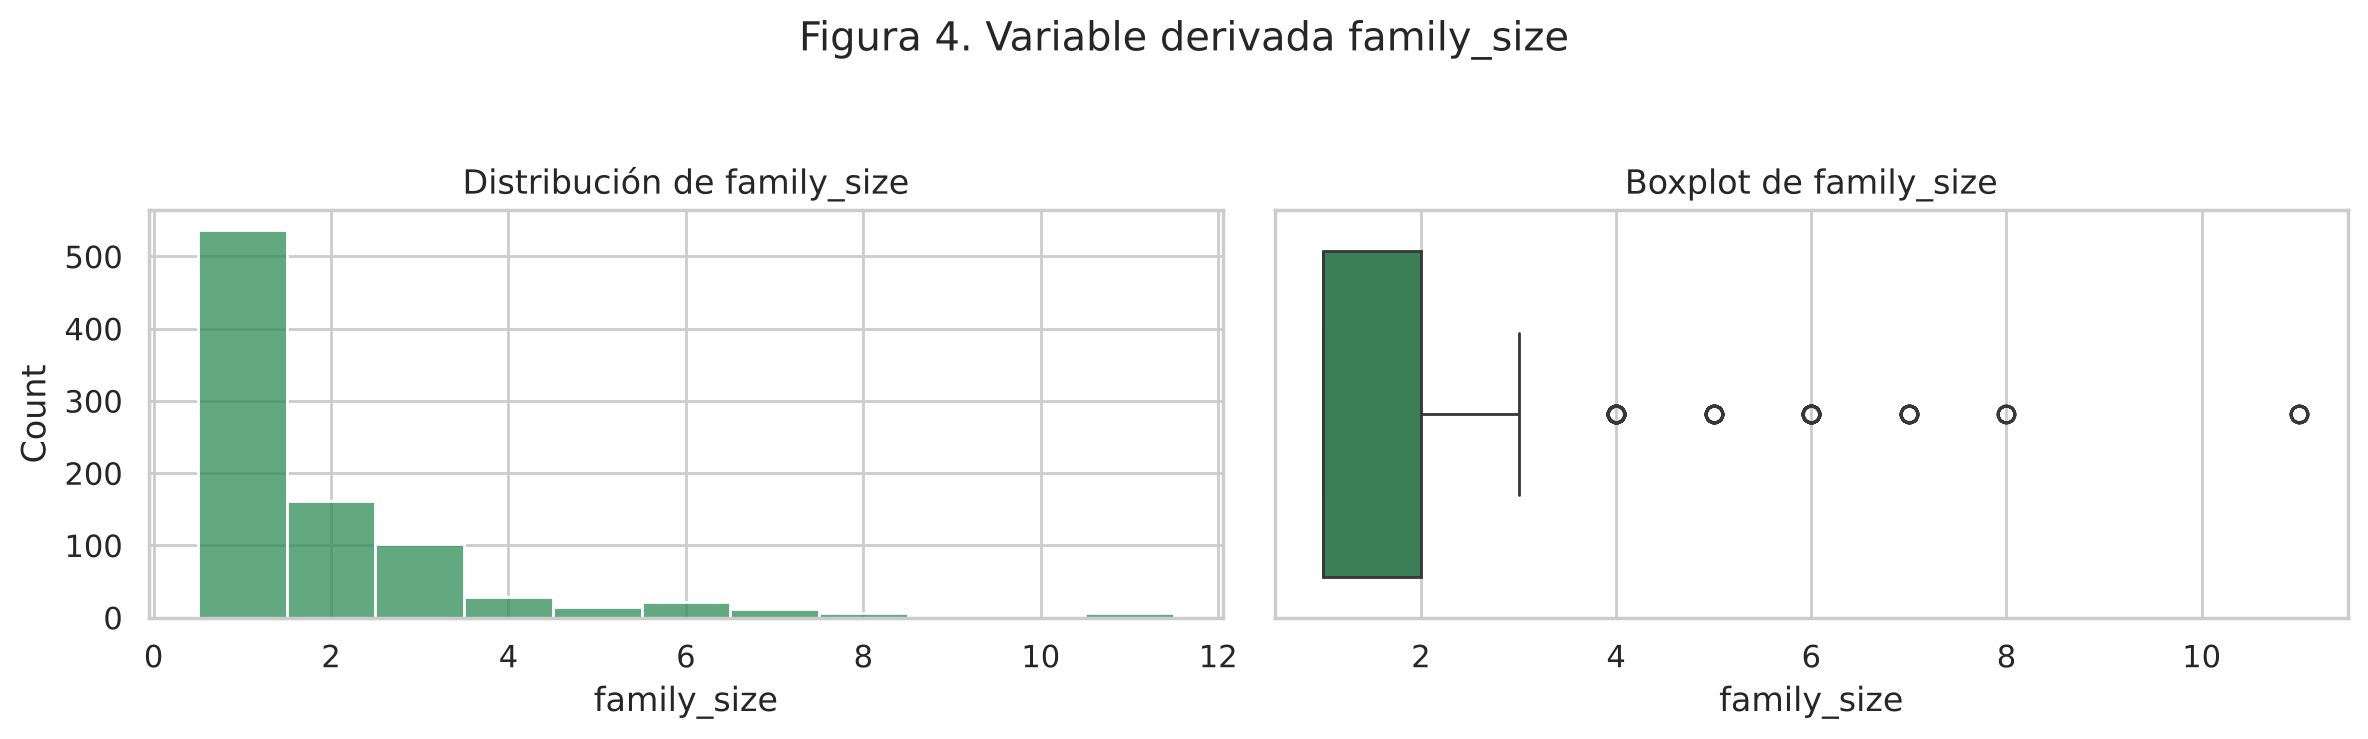

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
sns.histplot(titanic_eda["family_size"], discrete=True, ax=axes[0], color="seagreen")
axes[0].set_title("Distribución de family_size")
sns.boxplot(x=titanic_eda["family_size"], ax=axes[1], color="seagreen")
axes[1].set_title("Boxplot de family_size")
fig.suptitle("Figura 4. Variable derivada family_size", y=1.05)
plt.tight_layout()
plt.show()

`family_size` evidencia que predominan viajeros individuales (`1`) y grupos pequeños (`2` a `4`), con familias numerosas poco frecuentes.

## Registro consolidado de decisiones
Tabla de trazabilidad de la fase (se cita en el informe PDF).

In [25]:
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(registro_decisiones)

,ID,Tema,Decisión,Justificación,Resultado intermedio
0,D1,Duplicados,✍️ COMPLETAR,✍️ COMPLETAR,Filas tras D1: 891
1,D2,Columnas redundantes,Se descartan: [],✍️ COMPLETAR,Columnas tras D2: 15
2,D3,Nulos en deck,✍️ COMPLETAR,✍️ COMPLETAR,Nulos en deck tras D3: 688
3,D4,Nulos en age,✍️ COMPLETAR,✍️ COMPLETAR,Nulos en age tras D4: 177
4,D5,Nulos en embarked,✍️ COMPLETAR,✍️ COMPLETAR,Nulos en embarked tras D5: 2
5,D6,Variable derivada,Se crea family_size = sibsp + parch + 1,Resume en una sola medida el tamaño del grupo familiar a bordo,family_size: rango 1–11


In [26]:
pd.DataFrame({
    "titanic_raw": [titanic_raw.shape[0], titanic_raw.shape[1], int(titanic_raw.isna().sum().sum())],
    "titanic_eda": [titanic_eda.shape[0], titanic_eda.shape[1], int(titanic_eda.isna().sum().sum())],
}, index=["filas", "columnas", "nulos_totales"])

,titanic_raw,titanic_eda
filas,891,891
columnas,15,16
nulos_totales,869,869


# VI. Resultados e interpretación inicial

Una vez comprendidas las variables por separado, se explora cómo se relacionan con la variable de interés (`survived`). Combinar tablas de resumen con gráficos comparativos evita quedarse solo con impresiones visuales.
Recordatorio: *explorar no es confirmar*; aquí se describen patrones, sin pruebas de hipótesis.

## VI.1 Supervivencia según sexo y clase  ·  *(P3)*

In [27]:
print("Tasa de supervivencia por sexo y clase:")
titanic_eda.pivot_table(index="class", columns="sex", values="survived",
                        aggfunc="mean", observed=False).round(3)

Tasa de supervivencia por sexo y clase:


sex,female,male
class,,
First,0.968,0.369
Second,0.921,0.157
Third,0.500,0.135


## VI.2 Tarifa por clase y supervivencia por tamaño familiar  ·  *(P4)*

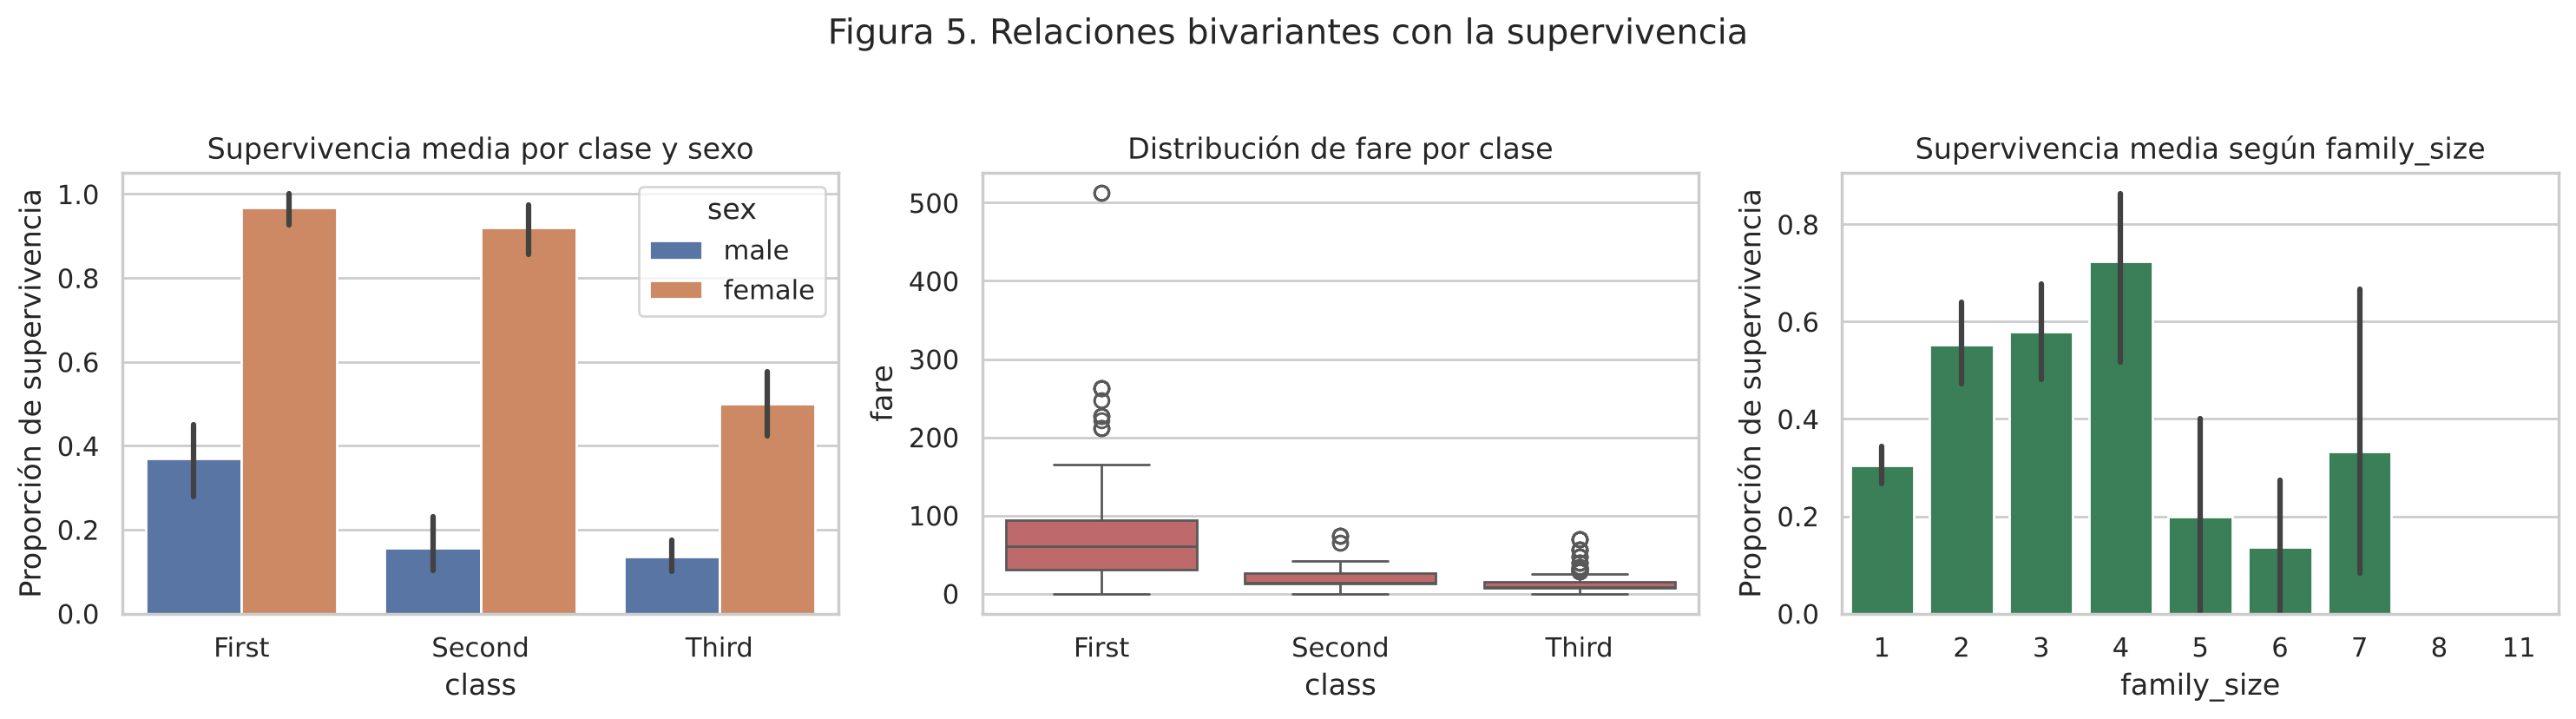

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=titanic_eda, x="class", y="survived", hue="sex", ax=axes[0],
            order=["First", "Second", "Third"])
axes[0].set_title("Supervivencia media por clase y sexo")
axes[0].set_ylabel("Proporción de supervivencia")

sns.boxplot(data=titanic_eda, x="class", y="fare", ax=axes[1], color="indianred",
            order=["First", "Second", "Third"])
axes[1].set_title("Distribución de fare por clase")

sns.barplot(data=titanic_eda, x="family_size", y="survived", ax=axes[2], color="seagreen")
axes[2].set_title("Supervivencia media según family_size")
axes[2].set_ylabel("Proporción de supervivencia")

fig.suptitle("Figura 5. Relaciones bivariantes con la supervivencia", y=1.03)
plt.tight_layout()
plt.show()

## VI.3 Control del tamaño de los grupos
Una tasa calculada sobre pocos casos es inestable. Antes de interpretar la Figura 5 (panel derecho) se revisa cuántos pasajeros respaldan cada tasa y cómo se reparten las familias por clase.

In [29]:
tabla_fs = titanic_eda.groupby("family_size")["survived"].agg(n="count", tasa_supervivencia="mean").round(2)
tabla_fs

,n,tasa_supervivencia
family_size,,
1,537,0.30
2,161,0.55
3,102,0.58
4,29,0.72
5,15,0.20
6,22,0.14
7,12,0.33
8,6,0.00
11,7,0.00


In [30]:
pd.crosstab(titanic_eda["family_size"], titanic_eda["class"], normalize="index").round(2)

class,First,Second,Third
family_size,,,
1,0.20,0.19,0.60
2,0.43,0.21,0.35
3,0.24,0.30,0.46
4,0.24,0.45,0.31
5,0.13,0.07,0.80
6,0.18,0.05,0.77
7,0.00,0.00,1.00
8,0.00,0.00,1.00
11,0.00,0.00,1.00


### Síntesis de hallazgos iniciales del EDA
- **Calidad de datos (P1):** existen valores faltantes relevantes en `deck` y `age`, 107 filas duplicadas sin identificador que permita resolverlas y varias columnas redundantes; todo ello se registra como decisión en la sección V.
- **Asimetrías (P2):** `fare` tiene una fuerte cola derecha, impulsada principalmente por los pasajeros de primera clase.
- **Supervivencia (P3):** la supervivencia muestra diferencias marcadas por `sex` y `class`.
- **Tamaño familiar (P4):** los grupos de 2 a 4 integrantes presentan mayor proporción de supervivencia que quienes viajan solos. La baja supervivencia de las familias numerosas debe leerse con cautela: esas tasas descansan en grupos de muy pocos pasajeros (Tabla VI.3) concentrados en tercera clase, por lo que la clase podría explicar parte del patrón.

✍️ COMPLETAR/AJUSTAR con las cifras finales una vez tomadas las decisiones D1–D5.

| Pregunta | Acción (sección) | Resultado principal |
|---|---|---|
| P1 | §III.3, §V | ✍️ |
| P2 | §IV.2, D6 | ✍️ |
| P3 | §VI.1 | ✍️ |
| P4 | §VI.2–VI.3 | ✍️ |

# VII. Supuestos y limitaciones

## VII.1 Supuestos
- La versión del dataset distribuida por seaborn representa adecuadamente a los pasajeros incluidos.
- Las filas idénticas sin identificador pueden corresponder a pasajeros distintos (pendiente D1).
- ✍️ COMPLETAR (supuestos asociados a las decisiones D3–D5).

## VII.2 Limitaciones
- El dataset no incluye a todas las personas a bordo (p. ej., la tripulación) ni identificadores de pasajero.
- `deck` tiene ~77 % de valores faltantes y `age` ~20 %, con ausencia que varía por clase.
- El análisis es descriptivo: los patrones observados no implican relaciones causales.
- ✍️ COMPLETAR.

## VII.3 Aspectos pendientes para fases posteriores
✍️ COMPLETAR (p. ej., imputación más fina de `age`, tratamiento de outliers de `fare`, nuevas variables derivadas).

# VIII. Cierre del avance

**Síntesis del trabajo realizado:** ✍️ COMPLETAR (3-4 líneas).

**Principales hallazgos de la fase:** ✍️ COMPLETAR (3 viñetas con referencia a figura o tabla).

**Continuidad del proyecto:** ✍️ COMPLETAR.

## Evidencia de reproducibilidad

In [31]:
RUTA_SALIDA = raiz_proyecto / "datos" / "titanic_eda_f1.csv"
titanic_eda.to_csv(RUTA_SALIDA, index=False)

print("Archivo de entrada :", RUTA_DATOS.relative_to(raiz_proyecto), titanic_raw.shape)
print("Archivo de salida  :", RUTA_SALIDA.relative_to(raiz_proyecto), titanic_eda.shape)
print("Decisiones registradas:", len(registro_decisiones))

Archivo de entrada : datos/titanic.csv (891, 15)
Archivo de salida  : datos/titanic_eda_f1.csv (891, 16)
Decisiones registradas: 6


## Referencias
- Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical statistics for data scientists* (2.ª ed.). O'Reilly Media.
- Paraíso, S. (2026). *Resumen aplicado del libro: EDA mínimo viable* [Apunte]. Universidad Andrés Bello.
- The pandas development team. (2024). *pandas documentation*. https://pandas.pydata.org/docs/
- Waskom, M. L. (2021). seaborn: Statistical data visualization. *Journal of Open Source Software, 6*(60), 3021. https://doi.org/10.21105/joss.03021
- Waskom, M. (s. f.). *seaborn-data* [Repositorio de datos]. GitHub. https://github.com/mwaskom/seaborn-data